# 22. Which moved, the camera or the splat?

[Course plan](../../README.md)

An orange splat slides to the right between two exposures. It could be travelling across a table. The same shift appears if the table stays put and the camera moves left. A fixed blue mark and a second camera give the two explanations different fingerprints.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dynamic_motion.py").is_file())
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import dynamic_motion as motion
from dynamic_motion_demos import motion_figure, motion_lab
lang = 'en'

## Two shutters

Cameras A and B face straight ahead on a moving bar. B sits 0.8 m to the right of A. The orange splat and blue mark are 4 m deep. The time control sets the instant A fires. With zero delay, B fires at exactly the same instant. Turning on the screen adds an opaque strip halfway to the splat.

In [2]:
display(motion_lab(22, lang))

## What one exposure measures

At time zero the splat sits directly in front of A. In 0.8 seconds at 1 m/s it travels $1\cdot0.8=0.8$ m. Positive means right. With A stationary, the horizontal offset from the camera is 0.8 m. The depth is $Z=4$ m, giving a ray slope of $0.8/4=0.2$. The focal length $f=80$ pixels turns that slope into $80\cdot0.2=16$ pixels. The central column is $u_0=48$, so the splat lands at $48+16=64$.

In a second shot the splat stays put and A moves left by 0.8 m. Their positions still differ by $0-(-0.8)=0.8$ m. Both stories put orange at 64. The blue mark is fixed at $X=-1.2$ m. In the first story it lands at $48+80(-1.2)/4=24$. In the second it lands at $48+80(-1.2+0.8)/4=40$. There is now a visible way to tell the motions apart.

Here is the common calculation. At time $t$ in seconds, $X(t)$ is the horizontal position of the splat and $C(t)$ that of the camera, both in metres. For constant positive depth the lengths in the fraction cancel. The answer $u(t)$ is in pixels.

$$
u(t)=u_0+f\frac{X(t)-C(t)}{Z}.
$$

In [3]:
for object_speed, camera_speed in [(1, 0), (0, -1), (1, 1)]:
    left = motion.observing_pair(.8, object_speed, camera_speed)[0][0]
    print(f"v = {object_speed:+d}, camera = {camera_speed:+d} m/s   orange = {left['u']:.1f}, blue = {left['anchor']:.1f} px")

v = +1, camera = +0 m/s   orange = 64.0, blue = 24.0 px
v = +0, camera = -1 m/s   orange = 64.0, blue = 40.0 px
v = +1, camera = +1 m/s   orange = 48.0, blue = 8.0 px


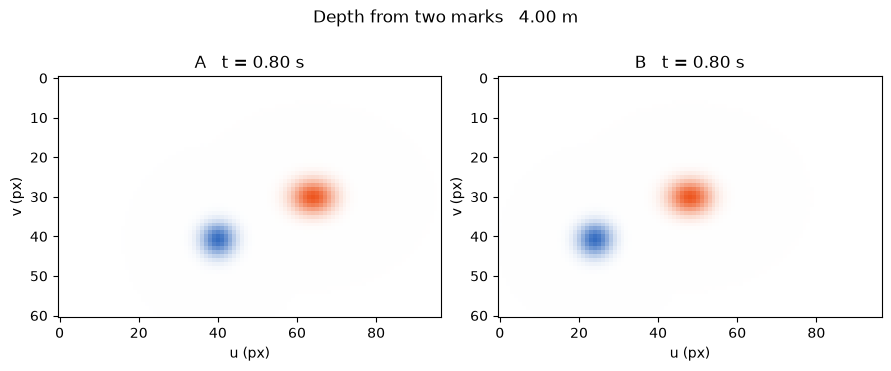

In [4]:
fig = motion_figure(22, lang, time=.8, object_speed=0, camera_speed=-1)
plt.show()

## Where the wrong depth comes from

With a stationary bar, A sees orange at 64. At the same instant B sits at $C_B=0.8$ m, directly opposite the splat, so $u_B=48$. The difference $d=u_A-u_B=16$ pixels is called disparity. Subtracting two projections of the **same position** cancels the splat coordinate $X$. The horizontal camera separation $b=C_B-C_A$ remains. For positive $d$ this gives

$$
\begin{aligned}
d&=\frac{f}{Z}\big((X-C_A)-(X-C_B)\big)=\frac{fb}{Z},\\
Z&=\frac{fb}{d}=\frac{80\cdot0.8}{16}=4\ \mathrm{m}.
\end{aligned}
$$

Now B fires 0.2 seconds late. The splat has reached $X=1$ m. Camera B sees $48+80(1-0.8)/4=52$. Treating these as synchronized samples gives $64/(64-52)=5.33$ m. Both recorded pixel positions are correct, but their rays met the splat at different times. A delay of 0.8 s makes the disparity zero. Dividing by zero yields no finite depth.

In [5]:
for lag in [0, .2, .8]:
    views, disparity, z = motion.observing_pair(lag=lag)
    print('Δt', lag, 's   u', [round(v['u'], 2) for v in views], 'px   d', round(disparity, 2), 'px   Z', z)

Δt 0 s   u [64.0, 48.0] px   d 16.0 px   Z 4.0
Δt 0.2 s   u [64.0, 52.0] px   d 12.0 px   Z 5.333333333333333
Δt 0.8 s   u [64.0, 64.0] px   d 0.0 px   Z None


## What the frames leave out

The screen is 2 m away and the splat is 4 m away. Halfway along a ray, the horizontal coordinate is the average of its endpoints. For A this is $(0+0.8)/2=0.4$ m, inside the opaque interval from 0.28 to 0.52 m. For B it is $(0.8+0.8)/2=0.8$ m, beyond the edge. The right frame still shows the center. In the left frame it is hidden. An orange tail peeking around an edge does not by itself give the hidden center's position.

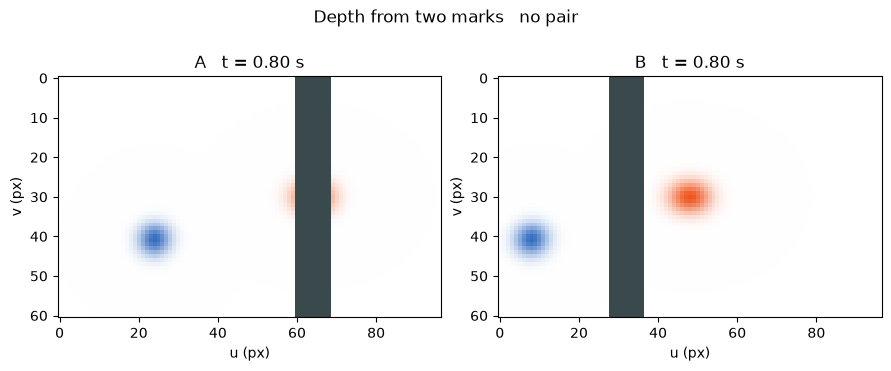

In [6]:
fig = motion_figure(22, lang, gate=True)
plt.show()

**What is still unknown?** Two synchronized views recover the center at 0 and 2 s. Do those observations determine its position at one second?

<details><summary>Worked answer</summary>

Each pair constrains depth at its own exposure time. The interval between exposures is empty. The splat could move steadily, slow down or swing sideways and still reach the second position on time. Drawing a straight line between the centers adds a motion assumption. The next splat makes the cost of that assumption visible in pixels.

</details>